In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

#import numpy as np # linear algebra
#import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

#import os
#for dirname, _, filenames in os.walk('/kaggle/input'):
#    for filename in filenames:
#        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

#import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import re, json, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, models, callbacks
warnings.filterwarnings("ignore")

In [2]:
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
!pip install -q gradio

In [4]:
DATA_PATH    = "/content/drive/MyDrive/Consumer_Complaint_Project/complaints_processed.csv"
TEXT_COL     = "narrative"
LABEL_COL    = "product"
TOP_K        = 5
MAX_PER_CLASS= 5000
MAX_WORDS    = 20000
MAX_LEN      = 200
EMB_DIM      = 128
EPOCHS       = 10
BATCH        = 64
SEED         = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [5]:
df = pd.read_csv(DATA_PATH, usecols=[TEXT_COL, LABEL_COL])
print("Shape:", df.shape)
df = df.dropna(subset=[TEXT_COL, LABEL_COL])
df = df[df[TEXT_COL].str.strip().str.lower() != "name"]
df = df.drop_duplicates(subset=[TEXT_COL]).reset_index(drop=True)
print("After dropping nulls / 'name' rows / duplicates:", df.shape)
df.head()

Shape: (162421, 2)
After dropping nulls / 'name' rows / duplicates: (124471, 2)


,product,narrative
0,credit_card,purchase order day shipping amount receive pro...
1,credit_card,forwarded message date tue subject please inve...
2,retail_banking,forwarded message cc sent friday pdt subject f...
3,credit_reporting,payment history missing credit report speciali...
4,credit_reporting,payment history missing credit report made mis...


count    124471.000000
mean         87.170714
std         110.932033
min           1.000000
25%          31.000000
50%          58.000000
75%         104.000000
max        2685.000000
Name: n_words, dtype: float64


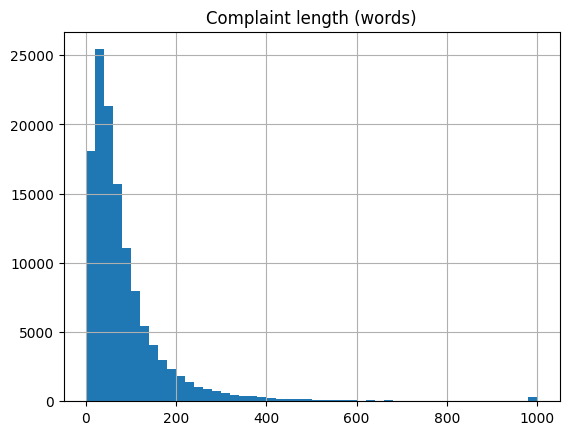

In [6]:
df["n_words"] = df[TEXT_COL].str.split().str.len()
print(df["n_words"].describe())
df["n_words"].clip(upper=1000).hist(bins=50)
plt.title("Complaint length (words)")
plt.show()

product
credit_reporting       56240
debt_collection        21056
mortgages_and_loans    18723
credit_card            14983
retail_banking         13469
Name: count, dtype: int64


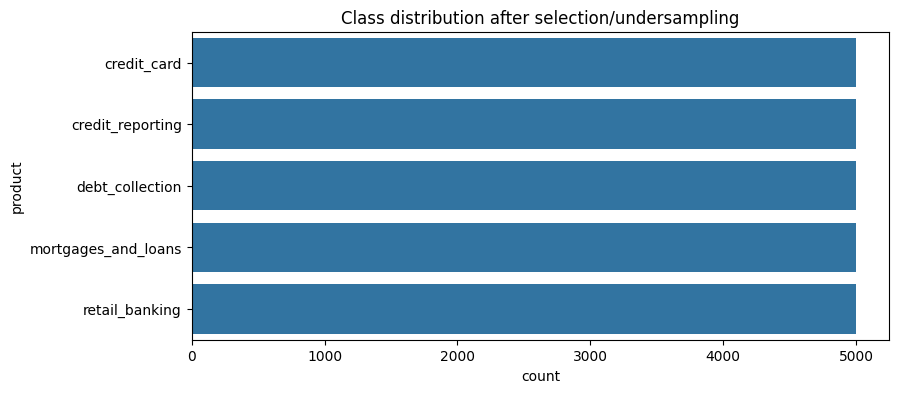

product
credit_card            5000
credit_reporting       5000
debt_collection        5000
mortgages_and_loans    5000
retail_banking         5000
Name: count, dtype: int64


In [7]:
print(df[LABEL_COL].value_counts())
top = df[LABEL_COL].value_counts().head(TOP_K).index
df = df[df[LABEL_COL].isin(top)]
df = pd.concat([g.sample(min(len(g), MAX_PER_CLASS), random_state=SEED)
for _, g in df.groupby(LABEL_COL)]).reset_index(drop=True)
plt.figure(figsize=(9,4))
sns.countplot(y=df[LABEL_COL], order=df[LABEL_COL].value_counts().index)
plt.title("Class distribution after selection/undersampling")
plt.show()
print(df[LABEL_COL].value_counts())

In [8]:
for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
STOP = set(stopwords.words("english"))
LEMM = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"x{2,}", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [LEMM.lemmatize(w) for w in text.split() if w not in STOP and len(w) > 2]
    return " ".join(tokens)

df["clean"] = df[TEXT_COL].apply(clean_text)
df = df[df["clean"].str.len() > 0].reset_index(drop=True)
print(df[[TEXT_COL, "clean"]].head(3).to_string())

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        narrative                                                                                       

In [9]:
le = LabelEncoder()
df["label"] = le.fit_transform(df[LABEL_COL])
CLASSES = list(le.classes_); NUM_CLASSES = len(CLASSES)

idx = np.arange(len(df))
tr_idx, test_idx = train_test_split(idx, test_size=0.2, stratify=df["label"], random_state=SEED)
tr_idx, val_idx  = train_test_split(tr_idx, test_size=0.125, stratify=df["label"].iloc[tr_idx], random_state=SEED)
print(len(tr_idx), len(val_idx), len(test_idx))
y = df["label"].values
y_train, y_val, y_test = y[tr_idx], y[val_idx], y[test_idx]

cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = dict(enumerate(cw)); print(class_weight)

17500 2500 5000
{0: np.float64(1.0), 1: np.float64(1.0), 2: np.float64(1.0), 3: np.float64(1.0), 4: np.float64(1.0)}


In [10]:
tok = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tok.fit_on_texts(df["clean"].iloc[tr_idx])
def to_seq(ix):
    return pad_sequences(tok.texts_to_sequences(df["clean"].iloc[ix]), maxlen=MAX_LEN, padding="post", truncating="post")
X_train, X_val, X_test = to_seq(tr_idx), to_seq(val_idx), to_seq(test_idx)
print(X_train.shape, X_val.shape, X_test.shape)

(17500, 200) (2500, 200) (5000, 200)



===== Training SimpleRNN =====
Epoch 1/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 35s 72ms/step - accuracy: 0.2053 - loss: 1.6124 - val_accuracy: 0.2200 - val_loss: 1.6044
Epoch 2/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 18s 20ms/step - accuracy: 0.2267 - loss: 1.5925 - val_accuracy: 0.2216 - val_loss: 1.6001
Epoch 3/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.2542 - loss: 1.5548 - val_accuracy: 0.2228 - val_loss: 1.6086
Epoch 4/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.2709 - loss: 1.5026 - val_accuracy: 0.2172 - val_loss: 1.6439

===== Training LSTM =====
Epoch 1/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.2137 - loss: 1.6061 - val_accuracy: 0.2128 - val_loss: 1.6077
Epoch 2/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 11s 41ms/step - accuracy: 0.2989 - loss: 1.5345 - val_accuracy: 0.3316 - val_loss: 1.4760
Epoch 3/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.3254 - loss: 1.4854 - val_accuracy: 0.3392 - val_loss: 1.4600
Epoch 4/10
274/274 ━━━━━━━━━━━━━━━

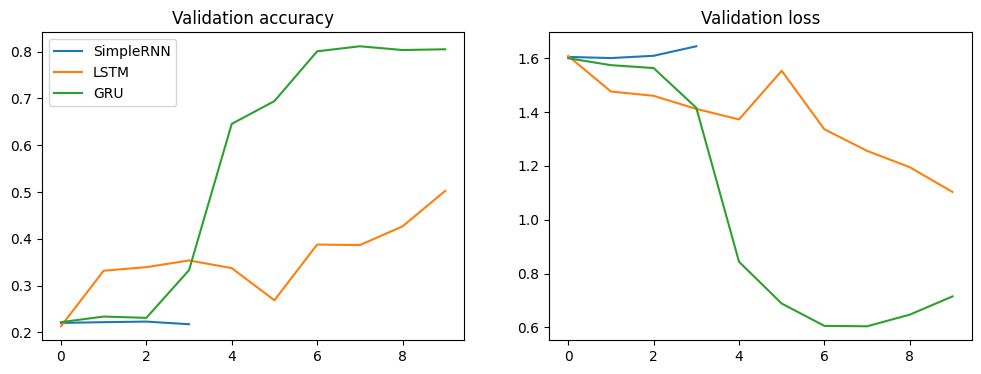

In [11]:
def build_model(cell, name):
    rec = {"SimpleRNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}[cell]
    m = models.Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(MAX_WORDS, EMB_DIM),
        rec(64),
        layers.Dropout(0.4),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name=name)
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

keras_models, histories = {}, {}
for cell in ["SimpleRNN", "LSTM", "GRU"]:
    print(f"\n===== Training {cell} =====")
    m = build_model(cell, cell)
    h = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCHS, batch_size=BATCH,
              class_weight=class_weight, verbose=1,
              callbacks=[callbacks.EarlyStopping(patience=2, restore_best_weights=True, monitor="val_loss")])
    keras_models[cell], histories[cell] = m, h

fig, ax = plt.subplots(1, 2, figsize=(12,4))
for k, h in histories.items():
    ax[0].plot(h.history["val_accuracy"], label=k); ax[1].plot(h.history["val_loss"], label=k)
ax[0].set_title("Validation accuracy"); ax[1].set_title("Validation loss")
ax[0].legend()
plt.show()

In [12]:
print(keras_models.keys())

dict_keys(['SimpleRNN', 'LSTM', 'GRU'])



=== SimpleRNN ===
                     precision    recall  f1-score   support

        credit_card       0.27      0.02      0.04      1000
   credit_reporting       0.40      0.00      0.01      1000
    debt_collection       0.21      0.93      0.34      1000
mortgages_and_loans       0.34      0.12      0.17      1000
     retail_banking       0.24      0.02      0.04      1000

           accuracy                           0.22      5000
          macro avg       0.29      0.22      0.12      5000
       weighted avg       0.29      0.22      0.12      5000



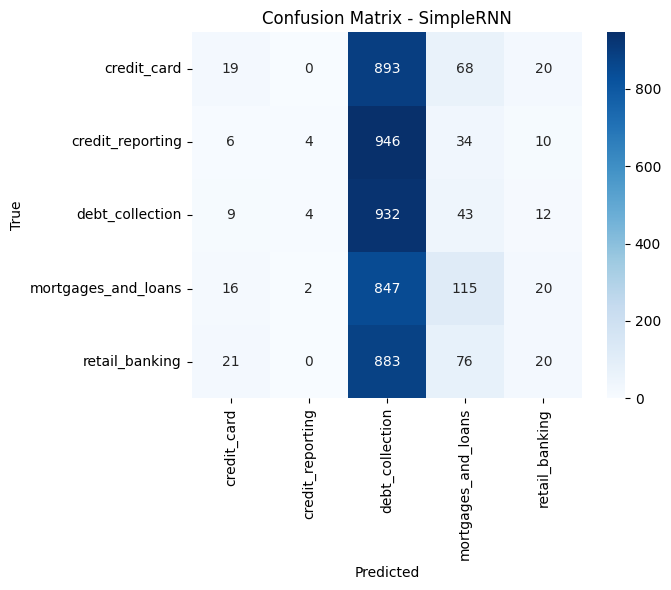


=== LSTM ===
                     precision    recall  f1-score   support

        credit_card       0.53      0.74      0.62      1000
   credit_reporting       0.42      0.02      0.04      1000
    debt_collection       0.47      0.81      0.59      1000
mortgages_and_loans       0.63      0.11      0.19      1000
     retail_banking       0.46      0.76      0.58      1000

           accuracy                           0.49      5000
          macro avg       0.50      0.49      0.40      5000
       weighted avg       0.50      0.49      0.40      5000



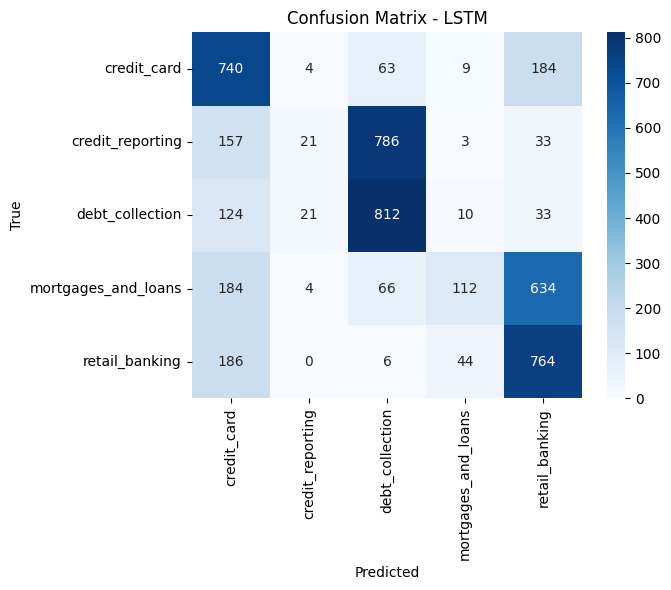


=== GRU ===
                     precision    recall  f1-score   support

        credit_card       0.80      0.80      0.80      1000
   credit_reporting       0.71      0.78      0.74      1000
    debt_collection       0.80      0.74      0.77      1000
mortgages_and_loans       0.83      0.86      0.85      1000
     retail_banking       0.88      0.83      0.86      1000

           accuracy                           0.80      5000
          macro avg       0.81      0.80      0.80      5000
       weighted avg       0.81      0.80      0.80      5000



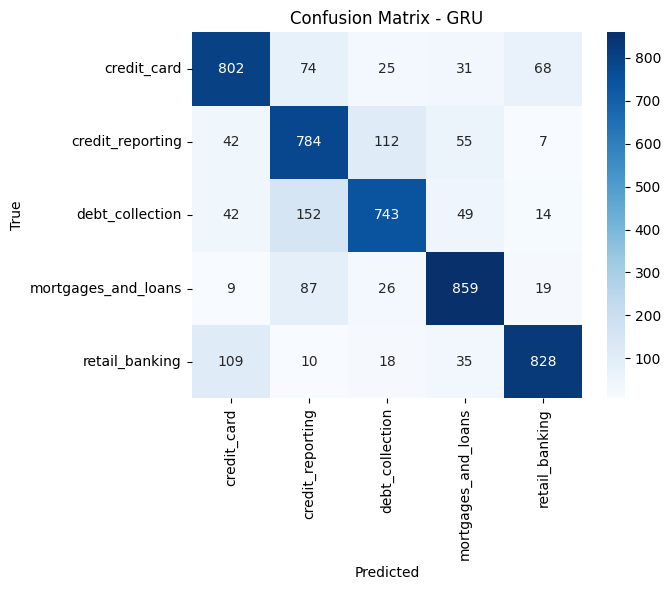

In [13]:
results = {}
def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    results[name] = {"Accuracy": acc, "Precision": p, "Recall": r, "F1-score": f1}
    print(f"\n=== {name} ===")
    print(classification_report(y_true, y_pred, target_names=CLASSES, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7,6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.show()

for name, m in keras_models.items():
    evaluate(name, y_test, m.predict(X_test, verbose=0).argmax(axis=1))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Training samples: 17500
Validation samples: 2500
Testing samples: 5000


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

... (4 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


=== DistilBERT (Fine-Tuned) ===
                     precision    recall  f1-score   support

        credit_card       0.85      0.83      0.84      1000
   credit_reporting       0.78      0.80      0.79      1000
    debt_collection       0.82      0.81      0.81      1000
mortgages_and_loans       0.86      0.85      0.86      1000
     retail_banking       0.87      0.90      0.89      1000

           accuracy                           0.84      5000
          macro avg       0.84      0.84      0.84      5000
       weighted avg       0.84      0.84      0.84      5000



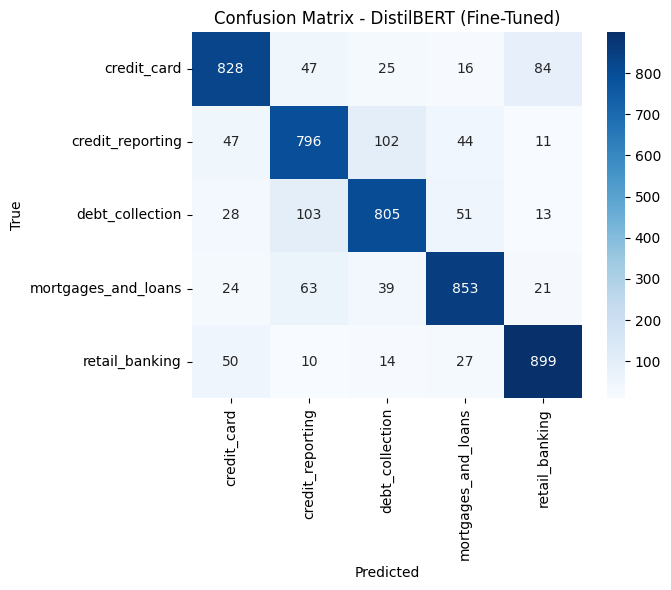

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully!


In [14]:
import torch
from transformers import AutoTokenizer , AutoModelForSequenceClassification , TrainingArguments , Trainer , DataCollatorWithPadding

MODEL_NAME = "distilbert-base-uncased"
TR_MAXLEN = 256

def light_clean(text):
    text = str(text).lower()
    text = re.sub(r"x{2,}" , " " , text)
    text = re.sub(r"\s+" , " " , text)

    return text.strip()

df["light"] = df[TEXT_COL].apply(light_clean)


hf_tok = AutoTokenizer.from_pretrained(MODEL_NAME)


class ComplaintDataset(torch.utils.data.Dataset):
    def __init__(self , indices):
        self.encodings = hf_tok(
            list(df["light"].iloc[indices]),
            truncation=True,
            padding=False,
            max_length=TR_MAXLEN
        )
        self.labels = np.asarray(y)[indices]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(values[idx])
            for key, values in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            int(self.labels[idx]),
            dtype=torch.long
        )

        return item

train_ds = ComplaintDataset(tr_idx)
val_ds = ComplaintDataset(val_idx)
test_ds = ComplaintDataset(test_idx)

print("Training samples:", len(train_ds))
print("Validation samples:", len(val_ds))
print("Testing samples:", len(test_ds))

data_collator = DataCollatorWithPadding(
    tokenizer=hf_tok,
    padding=True
)

def compute_metrics(eval_pred):
    logits = eval_pred.predictions
    true_labels = eval_pred.label_ids

    predictions = logits.argmax(axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    accuracy = accuracy_score(
        true_labels,
        predictions
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

hf_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels = NUM_CLASSES,
    id2label={
        idx: label
        for idx, label in enumerate(CLASSES)
    },

    label2id={
        label: idx
        for idx, label in enumerate(CLASSES)
    }
)

training_args = TrainingArguments(
    output_dir="hf_out",

    num_train_epochs = 3,

    per_device_train_batch_size = 16,
    per_device_eval_batch_size = 16,

    learning_rate=2e-5,
    weight_decay = 0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end = True,
    metric_for_best_model = "f1",
    greater_is_better=True,
    save_total_limit=2,
    report_to="none",


    fp16=torch.cuda.is_available()
)


trainer = Trainer(

    model=hf_model,

    args=training_args,

    train_dataset=train_ds,
    eval_dataset=val_ds,

    data_collator = data_collator,

    compute_metrics=compute_metrics
)

trainer.train()

pred_out = trainer.predict(test_ds)

test_predictions = pred_out.predictions.argmax(axis=-1)

evaluate(
    "DistilBERT (Fine-Tuned)",
    y_test,
    test_predictions
)

trainer.save_model("distilbert_complaint_model")
hf_tok.save_pretrained("distilbert_complaint_model")

print("Model saved successfully!")

,Accuracy,Precision,Recall,F1-score
DistilBERT (Fine-Tuned),0.8362,0.8362,0.8362,0.8361
GRU,0.8032,0.8061,0.8032,0.8038
LSTM,0.4898,0.5027,0.4898,0.4041
SimpleRNN,0.2180,0.2922,0.2180,0.1183


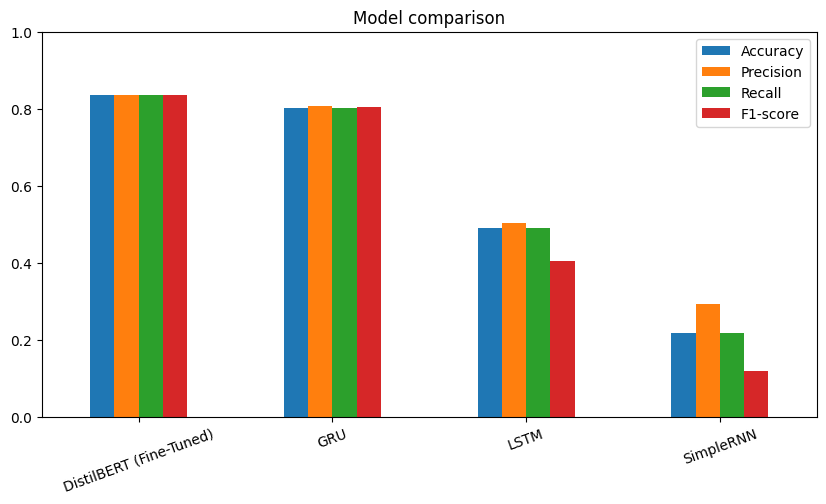

Best Model:  DistilBERT (Fine-Tuned)


In [15]:
comp = pd.DataFrame(results).T.sort_values(
    "F1-score",
    ascending=False
).round(4)

display(comp)

comp.plot(
    kind = "bar",
    figsize=(10,5),
    ylim=(0,1)
)

plt.title("Model comparison")
plt.xticks(rotation=20)
plt.legend(loc="upper right")
plt.show()

best_name = comp.index[0]
print("Best Model: ",best_name)

In [18]:
import os

ARTIFACTS_DIR = "/content/drive/MyDrive/Consumer_Complaint_Project/artifacts"
os.makedirs(ARTIFACTS_DIR , exist_ok = True)

info = {
    "classes" : CLASSES,
    "max_len" : MAX_LEN
}

if best_name.startswith("DistilBERT"):
    transformer_path = os.path.join(
        ARTIFACTS_DIR,
        "transformer"
    )
    trainer.save_model(transformer_path)
    hf_tok.save_pretrained(transformer_path)

    info["type"] = "transformer"

else:
    keras_model_path = os.path.join(
        ARTIFACTS_DIR,
        "keras_model.keras"
    )
    keras_models[best_name].save(keras_model_path)

    tokenizer_path = os.path.join(
        ARTIFACTS_DIR,
        "tokenizer.pkl"
    )
    with open(tokenizer_path, "wb") as file:
        pickle.dump(tok, file)

    info["type"] = "keras"


info_path = os.path.join(
    ARTIFACTS_DIR,
    "best_model_info.json"
)

with open(info_path , "w" , encoding="utf-8") as file:
    json.dump(
        info,
        file,
        ensure_ascii=False,
        indent=4
    )

print("Model saved successfully!")
print("Model Type:", info["type"])
print("Best Model:", best_name)
print("Artifacts Directory:", ARTIFACTS_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully!
Model Type: transformer
Best Model: DistilBERT (Fine-Tuned)
Artifacts Directory: /content/drive/MyDrive/Consumer_Complaint_Project/artifacts


In [17]:
def predict_complaint(text):



    if info["type"] == "transformer":


        enc = hf_tok(
            light_clean(text),
            return_tensors="pt",
            truncation=True,
            max_length=TR_MAXLEN
        ).to(trainer.model.device)


        with torch.no_grad():
            logits = trainer.model(**enc).logits


        probs = torch.softmax(logits, dim=-1)[0].cpu().numpy()

    else:

        sequence = tok.texts_to_sequences([
            clean_text(text)
        ])


        sequence = pad_sequences(
            sequence,
            maxlen=MAX_LEN,
            padding="post",
            truncating="post"
        )


        probs = keras_models[best_name].predict(
            sequence,
            verbose=0
        )[0]


    predicted_index = int(probs.argmax())
    predicted_class = CLASSES[predicted_index]
    confidence = float(probs.max())


    return predicted_class, confidence



samples = [
    "I was charged a late fee on my credit card even though I paid on time and nobody will fix it.",
    "The collector keeps calling me about a debt that is not mine.",
    "My mortgage servicer lost my payment and now threatens foreclosure."
]


for sample in samples:
    predicted_class, confidence = predict_complaint(sample)

    print(f"Complaint: {sample}")
    print(f"Predicted Category: {predicted_class}")
    print(f"Confidence Score: {confidence:.2%}")
    print("-" * 80)


Complaint: I was charged a late fee on my credit card even though I paid on time and nobody will fix it.
Predicted Category: credit_card
Confidence Score: 89.45%
--------------------------------------------------------------------------------
Complaint: The collector keeps calling me about a debt that is not mine.
Predicted Category: debt_collection
Confidence Score: 97.68%
--------------------------------------------------------------------------------
Complaint: My mortgage servicer lost my payment and now threatens foreclosure.
Predicted Category: mortgages_and_loans
Confidence Score: 93.34%
--------------------------------------------------------------------------------
